## LangGraph构建Agent
1. 顺序执行（Prompt Chaining）
2. 并行执行（Parallelization）
3. 路由（Routing）
4. Orchestrator-Worker + Send API
5. Evaluator-Optimizer（评估-优化循环）
6. 子图嵌套（Subgraphs）

笔记：https://my.feishu.cn/wiki/Et6Iw6JCVi3likksegBcnLamnog

视频：https://www.bilibili.com/video/BV178w1z7EHQ/?spm_id_from=333.788.player.switch&vd_source=4afb0374462e2a6a5fe3309f3b19500d&p=84

六种编排模式速查

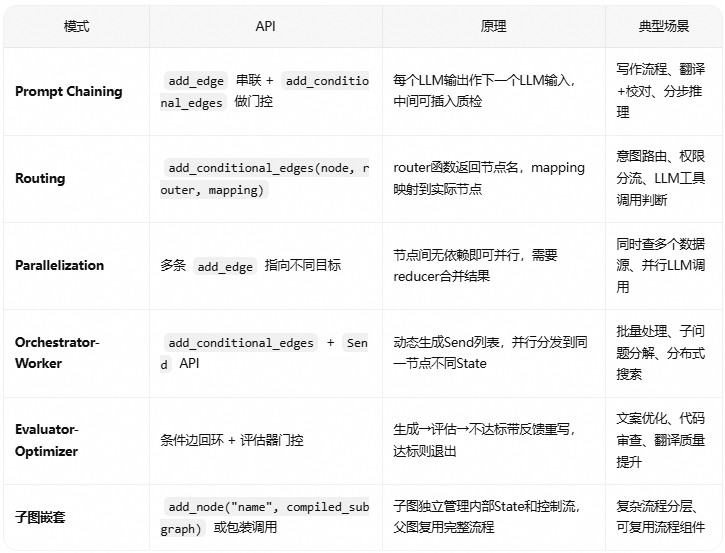

核心要点
- Prompt Chaining 是最简单的编排 — 串联LLM调用，中间加入门控检查，形成可验证的流水线
- 路由是智能的基础 — Agent通过add_conditional_edges根据State动态选择路径
- 并行提升性能 — 无依赖的节点可并行执行，用operator.add等reducer合并结果
- Orchestrator-Worker — 动态任务拆分与并行执行，是智能与效率的结合，需要Send API
- Evaluator-Optimizer保障质量 — 生成→评估→反馈→重写循环，直到达标
- 子图实现分层设计 — 复杂流程拆为独立子图，add_node(graph)直接嵌入，共享State自动映射

模式选择指南
- 确定步骤顺序 → Prompt Chaining
- 存在不同领域的Node → 智能路由(Routing)
- 多个独立任务加速 → 并行执行(Parallelization)
- 复杂任务动态拆分和性能提升 → Orchestrator-Worker(Send)
- 需要迭代优化质量 → Evaluator-Optimizer
- 流程太长需要拆解 → 子图嵌套

### 一、路由模式

Routing工作流处理用户输入，然后将它们引导到上下文相关的任务Node。这允许您为复杂的任务定义专门的流。例如：
- 智能电商客服，首先识别问题的类型，然后将请求路由到 售前咨询、退款、退货等对应的Node。
- 知识问答机器人，首先识别问题知识领域，然后将请求路由到不同领域对应的专业Node上。

所以路由本质上也是条件分支，让Graph根据问题动态选择下一节点。这是Agent智能决策的核心机制

例如，我们写三个工作节点：
- 天气节点：可以查询天气
- 新闻节点：可以查询新闻
- 翻译节点：可以翻译

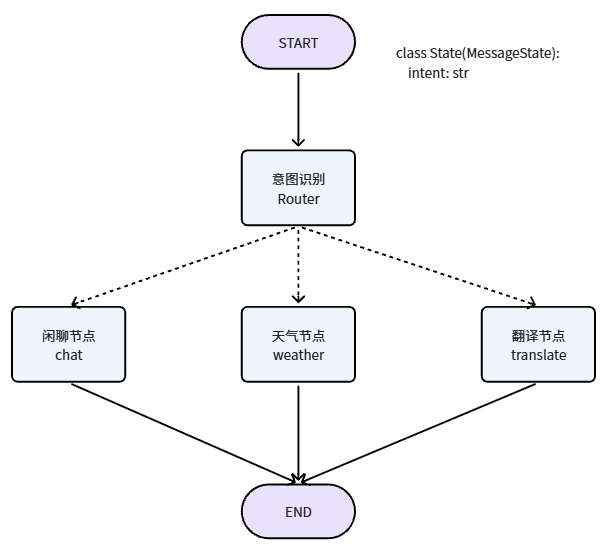

然后写一个`意图识别节点`，根据用户意图路由到对应的工作节点，执行对应任务：

In [4]:
from typing import Literal
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END, MessagesState
# ===============Step 1: 初始化chat模型===============
llm = init_chat_model(
    'deepseek-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)

# ===============Step 2: 定义State，记录用户输入、最终结果===============
class IntentState(MessagesState):
    intent: str

# ===============Step 4: 定义Node===============
def intent_node(state: IntentState):
    intent = llm.invoke(f'''
    根据用户的请求判断用户意图，可选意图：weather、translate或chat。
    user_query: {state['messages'][-1].content}
    ''')
    return {'intent': intent.text}

def weather_node(state: IntentState):
    return {'messages': [AIMessage(content='晴 25度')]}

def translate_node(state: IntentState):
    result = llm.invoke(f'''
    按照用户要求翻译，只输出翻译结果，不要任何解释。
    user_query:{state['messages'][-1].content}
    ''')
    return {'messages': [result]}

def chat_node(state: IntentState):
    result = llm.invoke(state['messages'])
    return {'messages': [result]}

def intent_router(state: IntentState) -> Literal['weather', 'translate', 'chat']:
    '''根据意图路由到不同处理器'''
    return state['intent']

# ===============Step 5: 创建Graph===============
builder = StateGraph(IntentState)
builder.add_node('intent', intent_node)
builder.add_node('weather', weather_node)
builder.add_node('chat', chat_node)
builder.add_node('translate', translate_node)

builder.add_edge(START, 'intent')
builder.add_conditional_edges('intent', intent_router)
builder.add_edge('weather', END)
builder.add_edge('chat', END)
builder.add_edge('translate', END)

routing_graph= builder.compile()

for q in ['今天北京天气如何？', '倍儿爽用英文怎么说', '你好']:
    r = routing_graph.invoke({'messages': [HumanMessage(content=q)]})
    print(f"'{q}' -> intent={r['intent']} -> {r['messages'][-1].content}")

'今天北京天气如何？' -> intent=weather -> 晴 25度
'倍儿爽用英文怎么说' -> intent=translate -> “倍儿爽” can be translated as “awesome,” “feeling great,” or “super refreshing,” depending on the context.
'你好' -> intent=chat -> 你好！很高兴见到你。有什么我可以帮忙的吗？无论是聊天、解决问题，还是需要一些建议，我都乐意协助！😊


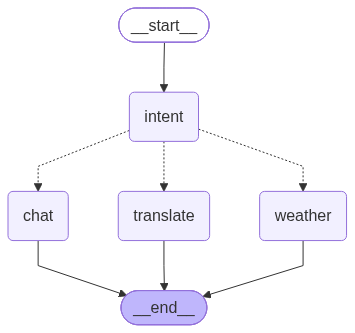

In [2]:
from IPython.display import Image, display
display(Image(routing_graph.get_graph(xray=True).draw_mermaid_png()))

### 二、子图嵌套